#  Physics-Informed Neural Networks for Adaptive Noise Cancellation

## Comparative Study: PINN vs Classical Adaptive Filtering Algorithms

---

> **Abstract:** This notebook presents a comprehensive comparison of a **Physics-Informed Neural Network (PINN)**-based adaptive filter against classical algorithms — **NLMS**, **TFLANN**, **APA**, and **RLS** — across three distinct system environments:
> 1. Linear System with AWGN  
> 2. Non-Linear System with AWGN  
> 3. Time-Varying System with AWGN  
>
> Performance is evaluated using **Mean Squared Error (dB) vs Time (samples)**.

---

###  Background

**Adaptive filters** are signal processing systems that self-adjust their parameters to minimize an error criterion. They are widely used in:
- Acoustic echo cancellation
- Noise suppression
- Channel equalization
- System identification

## Physics Loss: Temporal Smoothness Regularisation

For a sequence of predictions $\hat{y}(t)$ obtained from windows ending at times $t_1, t_2, \dots, t_K$ (with $t_{i+1} = t_i + 1$ sample), the **temporal smoothness loss** is defined as:

$$
\mathcal{L}_{\text{physics}} = \frac{1}{K-1} \sum_{i=1}^{K-1} \left( \hat{y}(t_{i+1}) - \hat{y}(t_i) \right)^2
$$

The total loss becomes:

$$
\mathcal{L}_{\text{total}} = \underbrace{\frac{1}{N}\sum_{i=1}^{N}\bigl(\hat{y}_i - d_i\bigr)^2}_{\text{Data loss}} \;+\; \lambda_{\text{smooth}} \cdot \underbrace{\frac{1}{K-1}\sum_{i=1}^{K-1}\bigl(\hat{y}(t_{i+1}) - \hat{y}(t_i)\bigr)^2}_{\text{Temporal smoothness}}
$$

where $\lambda_{\text{smooth}}$ is a hyperparameter that controls the strength of the physics‑informed regularisation.

This penalty encourages the network to produce a locally Lipschitz mapping from the input window to the output, improving generalisation and stability without requiring a PDE that does not fit the 1‑D time‑series setting.

---

###  Algorithms Compared

| Algorithm | Full Name | Key Parameter | Complexity |
|-----------|-----------|---------------|------------|
| **NLMS** | Normalized Least Mean Squares | Step size μ | O(N) |
| **TFLANN** | Trigonometric Functional Link ANN | Order + expansion | O(NP) |
| **APA** | Affine Projection Algorithm | Projection order K | O(KN) |
| **RLS** | Recursive Least Squares | Forgetting factor λ | O(N²) |
| **PINN** | Physics-Informed Neural Network | Wave eq. constraint | O(layers) |

---

##  Section 1: Installation & Imports

In [ ]:
# Install required libraries
!pip install torch torchvision torchaudio --quiet
!pip install matplotlib numpy scipy --quiet

print(" All packages installed successfully.")

 All packages installed successfully.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import signal
import torch
import torch.nn as nn
import torch.optim as optim
from torch.autograd import grad
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"  Using device: {device}")

# Plot style
plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor': '#161b22',
    'axes.edgecolor': '#30363d',
    'axes.labelcolor': '#e6edf3',
    'xtick.color': '#8b949e',
    'ytick.color': '#8b949e',
    'text.color': '#e6edf3',
    'grid.color': '#21262d',
    'grid.linestyle': '--',
    'grid.alpha': 0.5,
    'legend.facecolor': '#161b22',
    'legend.edgecolor': '#30363d',
    'font.family': 'monospace',
    'font.size': 10,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

# Color palette for algorithms
COLORS = {
    'NLMS':  '#58a6ff',
    'TFLANN':'#f78166',
    'APA':   '#3fb950',
    'RLS':   '#d2a8ff',
    'PINN':  '#ffa657',
}
print(" Imports complete.")

  Using device: cuda
 Imports complete.


---
##  Section 2: Signal Generation — Three System Environments

We define three environments to stress-test the adaptive filters under different conditions.

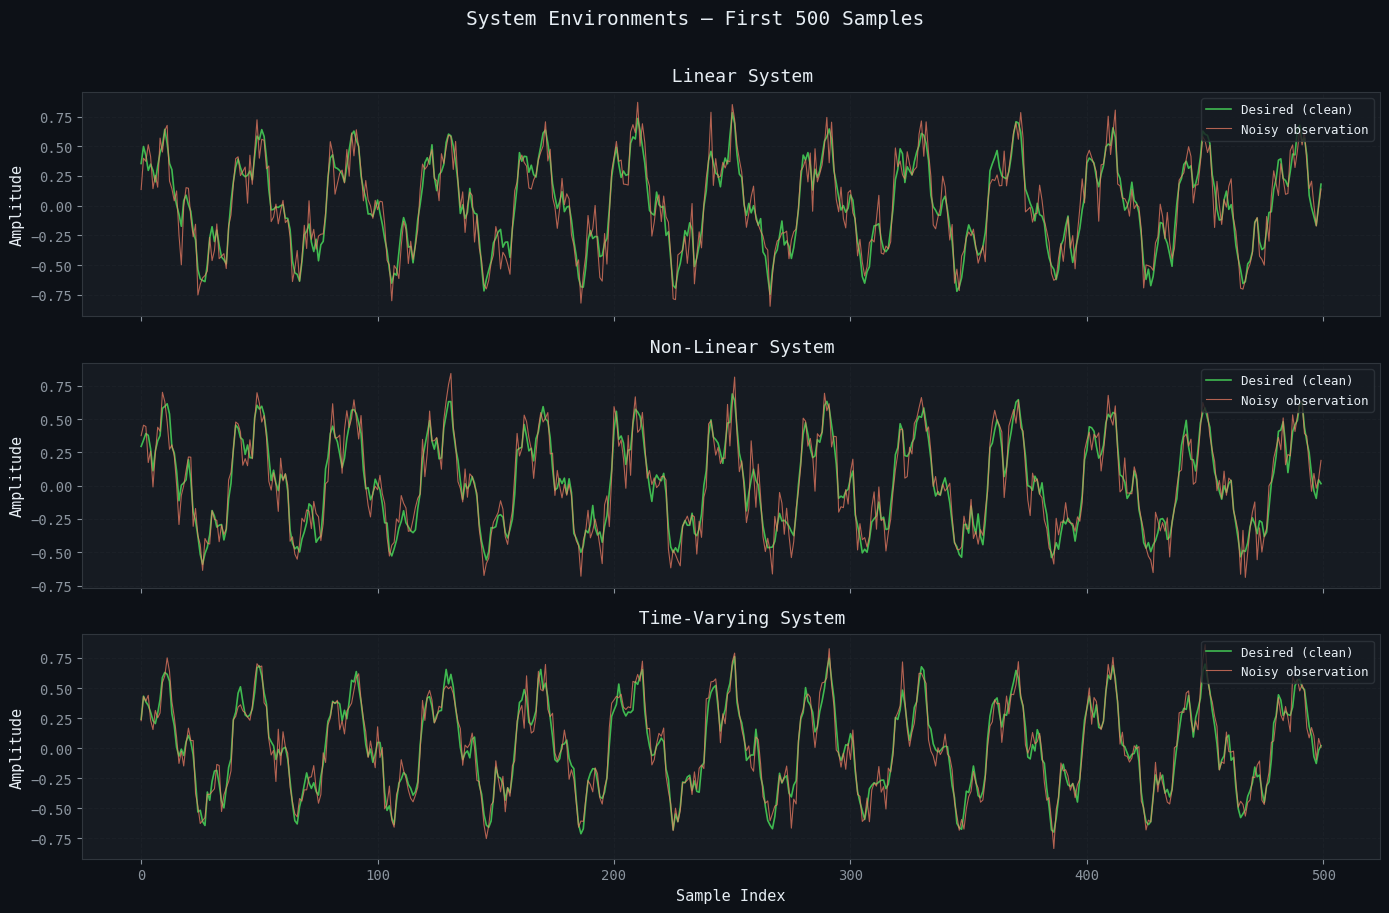

 Signal generation complete.


In [ ]:
def generate_signals(N=3000, snr_db=10, system_type='linear', fs=8000):
    """
    Generate input signal, desired signal, and noisy observation
    for three system types.

    Parameters
    ----------
    N           : number of samples
    snr_db      : signal-to-noise ratio in dB
    system_type : 'linear' | 'nonlinear' | 'timevarying'
    fs          : sampling frequency

    Returns
    -------
    x : input (reference) signal
    d : desired signal (clean)
    n : AWGN noise
    """
    t = np.arange(N) / fs

    # --- Input signal: narrowband + wideband mix ---
    x = (0.7 * np.sin(2 * np.pi * 200 * t) +
         0.3 * np.sin(2 * np.pi * 800 * t) +
         0.1 * np.random.randn(N))

    if system_type == 'linear':
        # FIR system: y[n] = 0.5x[n] + 0.3x[n-1] - 0.2x[n-2]
        h = np.array([0.5, 0.3, -0.2, 0.1, -0.05])
        d = np.convolve(x, h, mode='same')

    elif system_type == 'nonlinear':
        # Volterra-like nonlinear system
        h = np.array([0.5, 0.3, -0.2, 0.1, -0.05])
        d_lin = np.convolve(x, h, mode='same')
        # Add nonlinear terms: x^2 and x^3 cross-terms
        d = d_lin + 0.15 * d_lin**2 - 0.05 * d_lin**3
        d = np.tanh(d)  # soft saturation

    elif system_type == 'timevarying':
        # System coefficients change at t = N/3 and t = 2N/3
        d = np.zeros(N)
        seg = N // 3
        h1 = np.array([0.5, 0.3, -0.2, 0.1, -0.05])
        h2 = np.array([-0.3, 0.6,  0.1, -0.4,  0.2])
        h3 = np.array([0.1, -0.1,  0.5,  0.3, -0.3])
        d[:seg]      = np.convolve(x, h1, mode='same')[:seg]
        d[seg:2*seg] = np.convolve(x, h2, mode='same')[seg:2*seg]
        d[2*seg:]    = np.convolve(x, h3, mode='same')[2*seg:]
    else:
        raise ValueError(f"Unknown system_type: {system_type}")

    # Add AWGN
    signal_power = np.mean(d**2)
    noise_power  = signal_power / (10 ** (snr_db / 10))
    noise = np.sqrt(noise_power) * np.random.randn(N)
    return x.astype(np.float32), d.astype(np.float32), noise.astype(np.float32)


# Quick visualisation of the three systems
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
titles = ['Linear System', 'Non-Linear System', 'Time-Varying System']
sys_types = ['linear', 'nonlinear', 'timevarying']

for ax, title, stype in zip(axes, titles, sys_types):
    x, d, noise = generate_signals(N=3000, snr_db=10, system_type=stype)
    ax.plot(d[:500],           color='#3fb950', lw=1.2, label='Desired (clean)')
    ax.plot(d[:500]+noise[:500], color='#f78166', lw=0.8, alpha=0.7, label='Noisy observation')
    ax.set_title(f'  {title}', pad=8)
    ax.set_ylabel('Amplitude')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True)

axes[-1].set_xlabel('Sample Index')
fig.suptitle('System Environments — First 500 Samples', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('system_environments.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Signal generation complete.")

---
##  Section 3: Classical Adaptive Filter Implementations

### 3.1 NLMS — Normalized Least Mean Squares

The NLMS update rule normalises the step size by the input energy:

$$\mathbf{w}(n+1) = \mathbf{w}(n) + \frac{\mu}{\epsilon + \|\mathbf{x}(n)\|^2} e(n) \mathbf{x}(n)$$

where $e(n) = d(n) - \mathbf{w}^T(n)\mathbf{x}(n)$.

In [ ]:
def nlms_filter(x, d, M=32, mu=0.7, eps=1e-6):
    """
    Normalized Least Mean Squares (NLMS) adaptive filter.

    Parameters
    ----------
    x   : input (reference) signal, shape (N,)
    d   : desired signal, shape (N,)
    M   : filter order
    mu  : normalized step size (0 < mu < 2)
    eps : regularisation constant

    Returns
    -------
    e   : error signal
    mse : instantaneous squared error (linear)
    """
    N = len(x)
    w = np.zeros(M, dtype=np.float32)
    e = np.zeros(N, dtype=np.float32)

    x_buf = np.zeros(M, dtype=np.float32)  # circular buffer

    for n in range(N):
        x_buf = np.roll(x_buf, 1)
        x_buf[0] = x[n]

        y    = np.dot(w, x_buf)
        e[n] = d[n] - y

        norm = eps + np.dot(x_buf, x_buf)
        w   += (mu / norm) * e[n] * x_buf

    return e

print(" NLMS defined.")

 NLMS defined.


### 3.2 TFLANN — Trigonometric Functional Link Artificial Neural Network

TFLANN expands the input using trigonometric basis functions before applying LMS:

$$\phi_k(x) = \{x,\, \sin(\pi x),\, \cos(\pi x),\, \sin(2\pi x),\, \cos(2\pi x),\, \ldots\}$$

In [ ]:
def tflann_filter(x, d, M=16, P=2, mu=0.05, eps=1e-6):
    """
    Trigonometric Functional Link ANN (TFLANN) adaptive filter.

    Parameters
    ----------
    x   : input signal, shape (N,)
    d   : desired signal, shape (N,)
    M   : number of tapped delay line elements
    P   : trigonometric expansion order
    mu  : step size
    eps : regularisation constant

    Returns
    -------
    e   : error signal
    """
    N    = len(x)
    # Expanded feature size: M * (1 + 2P)
    L    = M * (1 + 2 * P)
    w    = np.zeros(L, dtype=np.float32)
    e    = np.zeros(N, dtype=np.float32)
    x_buf = np.zeros(M, dtype=np.float32)

    for n in range(N):
        x_buf = np.roll(x_buf, 1)
        x_buf[0] = x[n]

        # Build functional expansion
        phi = []
        for xk in x_buf:
            phi.append(xk)
            for p in range(1, P + 1):
                phi.append(np.sin(p * np.pi * xk))
                phi.append(np.cos(p * np.pi * xk))
        phi = np.array(phi, dtype=np.float32)

        y    = np.dot(w, phi)
        e[n] = d[n] - y

        norm = eps + np.dot(phi, phi)
        w   += (mu / norm) * e[n] * phi

    return e

print(" TFLANN defined.")

 TFLANN defined.


### 3.3 APA — Affine Projection Algorithm

APA projects onto an affine subspace spanned by K recent input vectors:

$$\mathbf{w}(n+1) = \mathbf{w}(n) + \mu\, \mathbf{X}(n) \left(\mathbf{X}^T(n)\mathbf{X}(n) + \epsilon \mathbf{I}\right)^{-1} \mathbf{e}(n)$$

In [ ]:
def apa_filter(x, d, M=32, K=4, mu=0.5, eps=1e-4):
    """
    Affine Projection Algorithm (APA).

    Parameters
    ----------
    x   : input signal
    d   : desired signal
    M   : filter order
    K   : projection order
    mu  : step size
    eps : regularisation

    Returns
    -------
    e   : error signal
    """
    N = len(x)
    w = np.zeros(M, dtype=np.float64)
    e = np.zeros(N, dtype=np.float32)

    # X_mat: columns are consecutive input vectors
    X_mat = np.zeros((M, K), dtype=np.float64)
    d_vec = np.zeros(K, dtype=np.float64)

    x_buf = np.zeros(M, dtype=np.float64)

    for n in range(N):
        x_buf    = np.roll(x_buf, 1)
        x_buf[0] = x[n]

        # Shift columns
        X_mat    = np.roll(X_mat, 1, axis=1)
        X_mat[:, 0] = x_buf

        d_vec    = np.roll(d_vec, 1)
        d_vec[0] = d[n]

        # Output vector
        y_vec    = X_mat.T @ w          # shape (K,)
        err_vec  = d_vec - y_vec
        e[n]     = float(err_vec[0])

        # APA weight update
        G = X_mat.T @ X_mat + eps * np.eye(K)
        try:
            delta_w = mu * X_mat @ np.linalg.solve(G, err_vec)
        except np.linalg.LinAlgError:
            delta_w = 0
        w += delta_w

    return e

print(" APA defined.")

 APA defined.


### 3.4 RLS — Recursive Least Squares

RLS minimises the weighted least squares cost with exponential forgetting:

$$\mathbf{P}(n) = \frac{1}{\lambda}\left[\mathbf{P}(n-1) - \frac{\mathbf{P}(n-1)\mathbf{x}(n)\mathbf{x}^T(n)\mathbf{P}(n-1)}{\lambda + \mathbf{x}^T(n)\mathbf{P}(n-1)\mathbf{x}(n)}\right]$$

$$\mathbf{w}(n) = \mathbf{w}(n-1) + \mathbf{P}(n)\mathbf{x}(n)\, e(n)$$

In [ ]:
def rls_filter(x, d, M=32, lam=0.98, delta=100.0, eps=1e-8):
    """
    Recursive Least Squares (RLS) adaptive filter.
    """
    N = len(x)
    w = np.zeros(M, dtype=np.float64)
    P = delta * np.eye(M, dtype=np.float64)
    e = np.zeros(N, dtype=np.float64)          # use float64 for error
    x_buf = np.zeros(M, dtype=np.float64)

    for n in range(N):
        x_buf = np.roll(x_buf, 1)
        x_buf[0] = x[n]

        y = np.dot(w, x_buf)
        e[n] = d[n] - y

        Px = P @ x_buf
        denom = lam + x_buf @ Px
        k = Px / (denom + eps)                 # add epsilon for safety

        w += k * e[n]
        P = (P - np.outer(k, Px)) / lam
        P = (P + P.T) / 2.0                   # enforce symmetry

    return e.astype(np.float32)
print(" RLS defined.")

 RLS defined.


---
##  Section 4: PINN — Physics-Informed Neural Network Adaptive Filter

### Architecture & Physics Constraint

The PINN processes a **sliding window** of the noisy input and produces a one-step prediction of the clean signal. The **wave equation residual** is enforced on collocation points sampled from the input trajectory.

$$
\mathcal{L}_{\text{total}} = \underbrace{\frac{1}{N}\sum_{i=1}^{N}\bigl(\hat{y}_i - d_i\bigr)^2}_{\text{Data loss}} \;+\; \lambda_{\text{smooth}} \cdot \underbrace{\frac{1}{K-1}\sum_{i=1}^{K-1}\bigl(\hat{y}(t_{i+1}) - \hat{y}(t_i)\bigr)^2}_{\text{Temporal smoothness}}
$$

In [ ]:
class PINNAdaptiveFilter(nn.Module):
    """
    Physics-Informed Neural Network for adaptive noise cancellation.

    Input  : (batch, M) — tapped-delay-line window
    Output : (batch, 1) — one-step clean signal prediction
    """
    def __init__(self, M=32, hidden_sizes=(128, 128, 64)):
        super().__init__()
        layers = []
        in_size = M
        for h in hidden_sizes:
            layers += [nn.Linear(in_size, h), nn.Tanh()]
            in_size  = h
        layers += [nn.Linear(in_size, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def temporal_smoothness_loss(model, x_t, t_indices, window_len=32):
    """
    Enforce that the network's predictions for overlapping windows
    are smooth in time. For each pair of consecutive windows (shifted by 1 sample),
    we penalize the squared difference of their outputs.

    Args:
        model: PINN module
        x_t: full input signal tensor (N,)
        t_indices: list of time indices where windows start
        window_len: M, the filter order

    Returns:
        smoothness_loss: scalar tensor
    """
    if len(t_indices) < 2:
        return torch.tensor(0.0, device=x_t.device)

    preds = []
    for idx in t_indices:
        if idx < window_len:
            pad = torch.zeros(window_len - idx - 1, device=x_t.device)
            win = torch.cat([pad, x_t[:idx+1]])
        else:
            win = x_t[idx - window_len + 1 : idx + 1]
        win = win.unsqueeze(0)  # (1, M)
        pred = model(win)       # (1, 1)
        preds.append(pred)

    # Pairwise differences between consecutive predictions
    diffs = [preds[i+1] - preds[i] for i in range(len(preds)-1)]
    loss = torch.mean(torch.stack([d**2 for d in diffs]))
    return loss


def pinn_adaptive_filter(x, d, M=32, epochs_per_step=5,
                         lr=1e-3, lambda_smooth=1e-6,
                         hidden_sizes=(128, 128, 64),
                         pretrain_steps=500):
    """
    PINN adaptive filter with temporal smoothness physics loss.
    """
    N = len(x)
    model = PINNAdaptiveFilter(M=M, hidden_sizes=hidden_sizes).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    mse_loss = nn.MSELoss()
    e = np.zeros(N, dtype=np.float32)

    x_t = torch.tensor(x, dtype=torch.float32).to(device)
    d_t = torch.tensor(d, dtype=torch.float32).to(device)

    def get_window(n):
        if n < M:
            pad = torch.zeros(M - n - 1, device=device)
            return torch.cat([pad, x_t[:n+1]])
        return x_t[n-M+1:n+1]

    # --- Pre-training ---
    print(" Pre-training PINN ...")
    for n in range(min(pretrain_steps, N-1)):
        win = get_window(n).unsqueeze(0)
        target = d_t[n].unsqueeze(0).unsqueeze(0)
        for _ in range(2):
            optimizer.zero_grad()
            pred = model(win)
            loss = mse_loss(pred, target)
            loss.backward()
            optimizer.step()

    # --- Temporal smoothness loss helper ---
    def temporal_smoothness_loss(t_indices):
        if len(t_indices) < 2:
            return torch.tensor(0.0, device=device)
        preds = []
        for idx in t_indices:
            win = get_window(idx).unsqueeze(0)
            preds.append(model(win))
        diffs = [preds[i+1] - preds[i] for i in range(len(preds)-1)]
        return torch.mean(torch.stack([d**2 for d in diffs]))

    # --- Online adaptation ---
    print(" Running online PINN adaptation ...")
    for n in range(N):
        win = get_window(n).unsqueeze(0)
        target = d_t[n].unsqueeze(0).unsqueeze(0)

        for _ in range(epochs_per_step):
            optimizer.zero_grad()

            # Data loss
            pred = model(win)
            loss_data = mse_loss(pred, target)

            # Physics loss: temporal smoothness over recent windows
            n_col = min(10, n)
            if n_col >= 2:
                indices = list(range(max(0, n - n_col), n + 1))
                loss_physics = temporal_smoothness_loss(indices)
            else:
                loss_physics = torch.tensor(0.0, device=device)

            loss_total = loss_data + lambda_smooth * loss_physics
            loss_total.backward()
            optimizer.step()

        with torch.no_grad():
            pred_val = model(win).item()
            e[n] = d[n] - pred_val

    return e

print(" PINN adaptive filter defined.")

 PINN adaptive filter defined.


---
##  Section 5: MSE Computation Helper

We compute a **smoothed MSE in dB** using an exponential moving average to reduce noise in the learning curves.

In [ ]:
def mse_db_smoothed(e, alpha=0.99, eps=1e-12):
    """
    Compute exponentially smoothed MSE in dB.

    mse_smooth[n] = alpha * mse_smooth[n-1] + (1 - alpha) * e[n]^2
    MSE_dB[n]     = 10 * log10(mse_smooth[n])

    Parameters
    ----------
    e     : error signal, shape (N,)
    alpha : smoothing factor (closer to 1 → more smoothing)
    eps   : floor to avoid log(0)

    Returns
    -------
    mse_db : smoothed MSE in dB, shape (N,)
    """
    N = len(e)
    mse_smooth = np.zeros(N)
    mse_smooth[0] = e[0] ** 2
    for n in range(1, N):
        mse_smooth[n] = alpha * mse_smooth[n - 1] + (1 - alpha) * e[n] ** 2
    return 10 * np.log10(mse_smooth + eps)


def steady_state_mse_db(e, tail_frac=0.2, eps=1e-12):
    """Mean MSE (dB) over the last tail_frac of the error signal."""
    tail = e[int(len(e) * (1 - tail_frac)):]
    return 10 * np.log10(np.mean(tail ** 2) + eps)


print(" MSE helper defined.")

 MSE helper defined.


---
##  Section 6: Experiment Runner

A unified runner that executes all five algorithms on a given system and collects results.

In [ ]:
def run_experiment(system_type, N=3000, snr_db=10,
                   M=32, smooth_alpha=0.995,
                   run_pinn=True):
    """
    Run all adaptive filters on a given system type.

    Parameters
    ----------
    system_type  : 'linear' | 'nonlinear' | 'timevarying'
    N            : number of samples
    snr_db       : input SNR in dB
    M            : adaptive filter order
    smooth_alpha : EMA smoothing factor for MSE curves
    run_pinn     : whether to run the PINN (slower)

    Returns
    -------
    results : dict mapping algorithm name -> (error, mse_db)
    """
    print(f"\n{'='*60}")
    print(f"  System: {system_type.upper()}  |  N={N}  |  SNR={snr_db} dB  |  M={M}")
    print(f"{'='*60}")

    x, d, noise = generate_signals(N=N, snr_db=snr_db, system_type=system_type)
    x_noisy = x + noise  # reference fed to all algorithms

    results = {}

    # ---- NLMS ----
    print("  Running NLMS  ...", end=' ')
    e_nlms = nlms_filter(x_noisy, d, M=M, mu=0.5)
    results['NLMS'] = (e_nlms, mse_db_smoothed(e_nlms, alpha=smooth_alpha))
    print(f"done  |  SS-MSE: {steady_state_mse_db(e_nlms):.2f} dB")

    # ---- TFLANN ----
    print("  Running TFLANN...", end=' ')
    e_tflann = tflann_filter(x_noisy, d, M=M//2, P=2, mu=0.02)
    results['TFLANN'] = (e_tflann, mse_db_smoothed(e_tflann, alpha=smooth_alpha))
    print(f"done  |  SS-MSE: {steady_state_mse_db(e_tflann):.2f} dB")

    # ---- APA ----
    print("  Running APA   ...", end=' ')
    e_apa = apa_filter(x_noisy, d, M=M, K=4, mu=0.5)
    results['APA'] = (e_apa, mse_db_smoothed(e_apa, alpha=smooth_alpha))
    print(f"done  |  SS-MSE: {steady_state_mse_db(e_apa):.2f} dB")

    # ---- RLS ----
    print("  Running RLS   ...", end=' ')
    e_rls = rls_filter(x_noisy, d, M=M, lam=0.98)
    results['RLS'] = (e_rls, mse_db_smoothed(e_rls, alpha=smooth_alpha))
    print(f"done  |  SS-MSE: {steady_state_mse_db(e_rls):.2f} dB")

    # ---- PINN ----
    if run_pinn:
        print("  Running PINN  ...")
        e_pinn = pinn_adaptive_filter(
            x_noisy, d, M=M,
            epochs_per_step=5,
            lr=5e-4,
            lambda_smooth=0.1,
            hidden_sizes=(128, 128, 64),
            pretrain_steps=500
        )
        results['PINN'] = (e_pinn, mse_db_smoothed(e_pinn, alpha=smooth_alpha))
        print(f"  done  |  SS-MSE: {steady_state_mse_db(e_pinn):.2f} dB")

    return results

print(" Experiment runner defined.")

 Experiment runner defined.


---
##  Section 7: Run All Three Experiments

In [ ]:
# ============================================================
# EXPERIMENT CONFIGURATION
# ============================================================
CONFIG = dict(
    N=3000,       # total samples
    snr_db=5,    # input SNR
    M=32,         # filter order
    smooth_alpha=0.995,
    run_pinn=True  # set False to skip PINN for quick testing
)

SYSTEMS = ['linear', 'nonlinear', 'timevarying']
all_results = {}

for sys_type in SYSTEMS:
    all_results[sys_type] = run_experiment(sys_type, **CONFIG)

print("\n All experiments complete!")


  System: LINEAR  |  N=3000  |  SNR=5 dB  |  M=32
  Running NLMS  ... done  |  SS-MSE: -20.78 dB
  Running TFLANN... done  |  SS-MSE: -18.33 dB
  Running APA   ... done  |  SS-MSE: -19.23 dB
  Running RLS   ... done  |  SS-MSE: -19.95 dB
  Running PINN  ...
 Pre-training PINN ...
 Running online PINN adaptation ...
  done  |  SS-MSE: -22.41 dB

  System: NONLINEAR  |  N=3000  |  SNR=5 dB  |  M=32
  Running NLMS  ... done  |  SS-MSE: -22.02 dB
  Running TFLANN... done  |  SS-MSE: -18.88 dB
  Running APA   ... done  |  SS-MSE: -20.25 dB
  Running RLS   ... done  |  SS-MSE: -20.36 dB
  Running PINN  ...
 Pre-training PINN ...
 Running online PINN adaptation ...
  done  |  SS-MSE: -24.97 dB

  System: TIMEVARYING  |  N=3000  |  SNR=5 dB  |  M=32
  Running NLMS  ... done  |  SS-MSE: -22.55 dB
  Running TFLANN... done  |  SS-MSE: -18.42 dB
  Running APA   ... done  |  SS-MSE: -20.58 dB
  Running RLS   ... done  |  SS-MSE: -22.73 dB
  Running PINN  ...
 Pre-training PINN ...
 Running online 

---
##  Section 8: MSE Learning Curve Plots

### 8.1 Individual System Plots

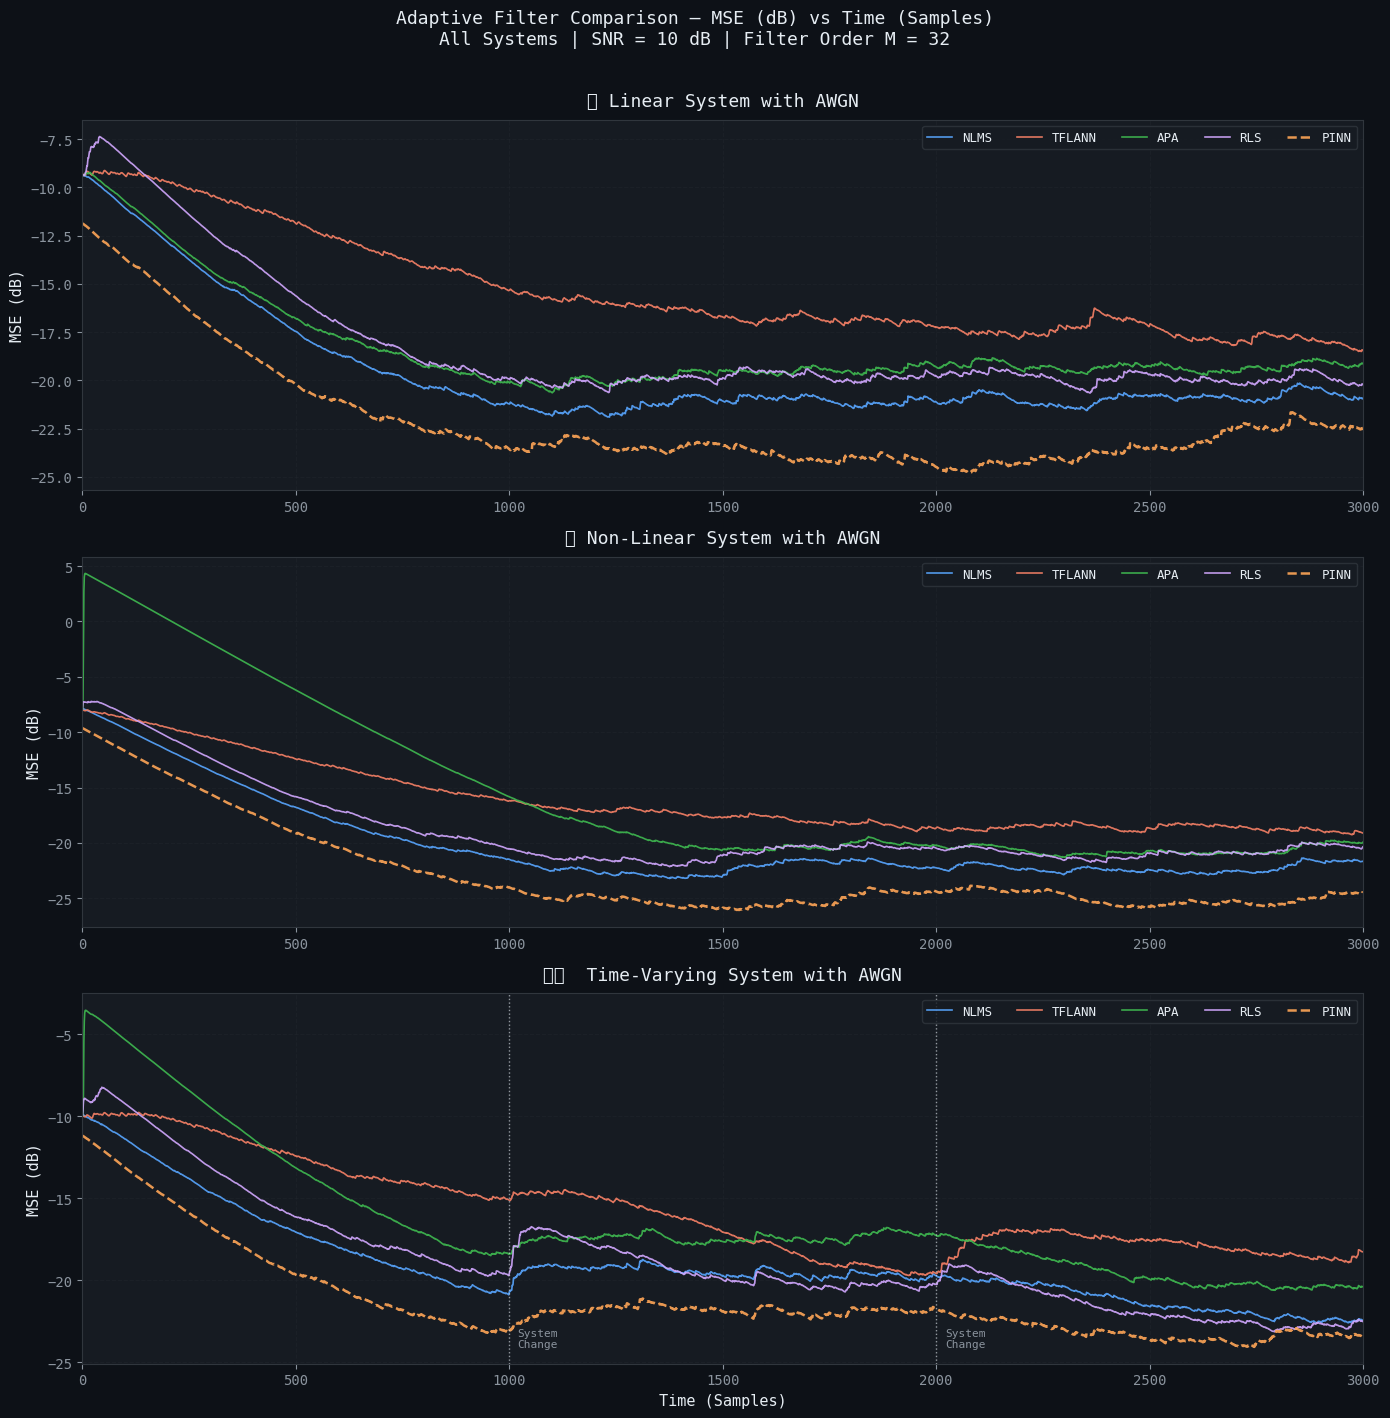

 MSE learning curve plots saved.


In [ ]:
SYSTEM_TITLES = {
    'linear':      '📐 Linear System with AWGN',
    'nonlinear':   '🔀 Non-Linear System with AWGN',
    'timevarying': '⏱️  Time-Varying System with AWGN',
}

fig, axes = plt.subplots(3, 1, figsize=(14, 14))

for ax, sys_type in zip(axes, SYSTEMS):
    res = all_results[sys_type]
    samples = np.arange(CONFIG['N'])

    for algo, (e, mse_curve) in res.items():
        ax.plot(samples, mse_curve,
                color=COLORS[algo],
                lw=1.8 if algo == 'PINN' else 1.2,
                ls='-' if algo != 'PINN' else '--',
                label=algo,
                alpha=0.9)

    # Mark system change-points for time-varying system
    if sys_type == 'timevarying':
        for cp in [CONFIG['N']//3, 2*CONFIG['N']//3]:
            ax.axvline(cp, color='#e6edf3', lw=1.0, ls=':', alpha=0.6)
            ax.text(cp+20, ax.get_ylim()[0]+1, 'System\nChange',
                    color='#8b949e', fontsize=8)

    ax.set_title(SYSTEM_TITLES[sys_type], pad=10)
    ax.set_ylabel('MSE (dB)')
    ax.legend(loc='upper right', fontsize=9, ncol=5)
    ax.grid(True)
    ax.set_xlim(0, CONFIG['N'])

axes[-1].set_xlabel('Time (Samples)')
fig.suptitle('Adaptive Filter Comparison — MSE (dB) vs Time (Samples)\nAll Systems | SNR = 10 dB | Filter Order M = 32',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('mse_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(" MSE learning curve plots saved.")

### 8.2 Combined 3×5 Grid — All Systems × All Algorithms

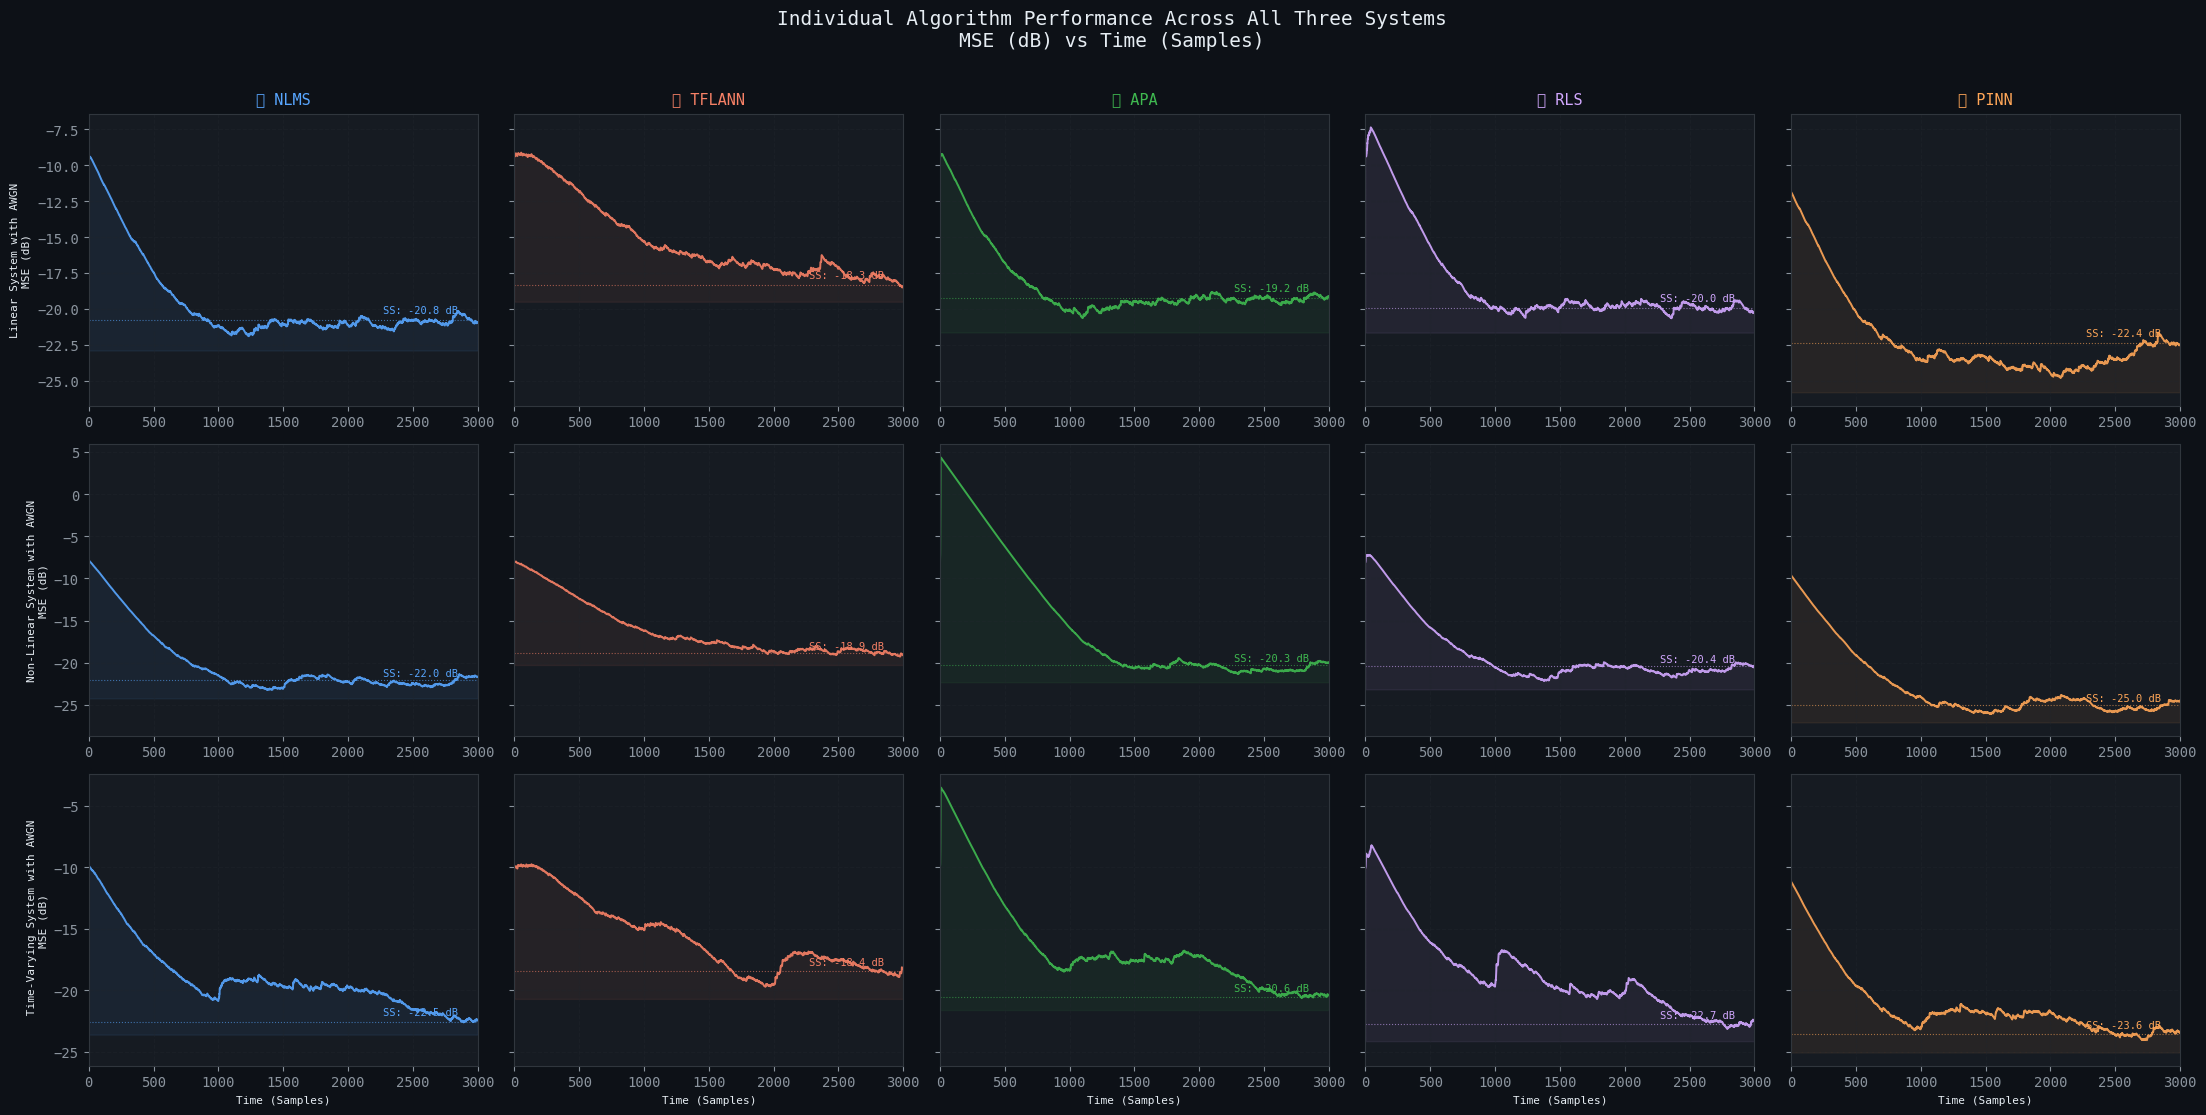

 Grid plot saved.


In [ ]:
ALGOS = list(COLORS.keys())
fig, axes = plt.subplots(3, 5, figsize=(22, 11), sharey='row')
samples = np.arange(CONFIG['N'])

for row, sys_type in enumerate(SYSTEMS):
    res = all_results[sys_type]
    sys_label = SYSTEM_TITLES[sys_type].split(' ', 1)[1]

    for col, algo in enumerate(ALGOS):
        ax = axes[row, col]
        if algo not in res:
            ax.text(0.5, 0.5, 'N/A', ha='center', va='center',
                    transform=ax.transAxes, color='#8b949e')
            continue

        _, mse_curve = res[algo]
        ax.plot(samples, mse_curve, color=COLORS[algo], lw=1.4, alpha=0.9)
        ax.fill_between(samples, mse_curve,
                         mse_curve.min() - 1,
                         color=COLORS[algo], alpha=0.07)

        ss_mse = steady_state_mse_db(res[algo][0])
        ax.axhline(ss_mse, color=COLORS[algo], lw=0.8, ls=':', alpha=0.6)

        ax.grid(True, alpha=0.4)
        ax.set_xlim(0, CONFIG['N'])

        if row == 0:
            ax.set_title(f'⭐ {algo}', color=COLORS[algo], fontsize=11, pad=8)
        if col == 0:
            ax.set_ylabel(f'{sys_label}\nMSE (dB)', fontsize=8)
        if row == 2:
            ax.set_xlabel('Time (Samples)', fontsize=8)

        # Steady-state annotation
        ax.annotate(f'SS: {ss_mse:.1f} dB',
                    xy=(CONFIG['N']*0.95, ss_mse + 0.5),
                    fontsize=7.5, color=COLORS[algo],
                    ha='right')

fig.suptitle('Individual Algorithm Performance Across All Three Systems\nMSE (dB) vs Time (Samples)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('mse_grid.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Grid plot saved.")

---
##  Section 9: Steady-State Performance Summary

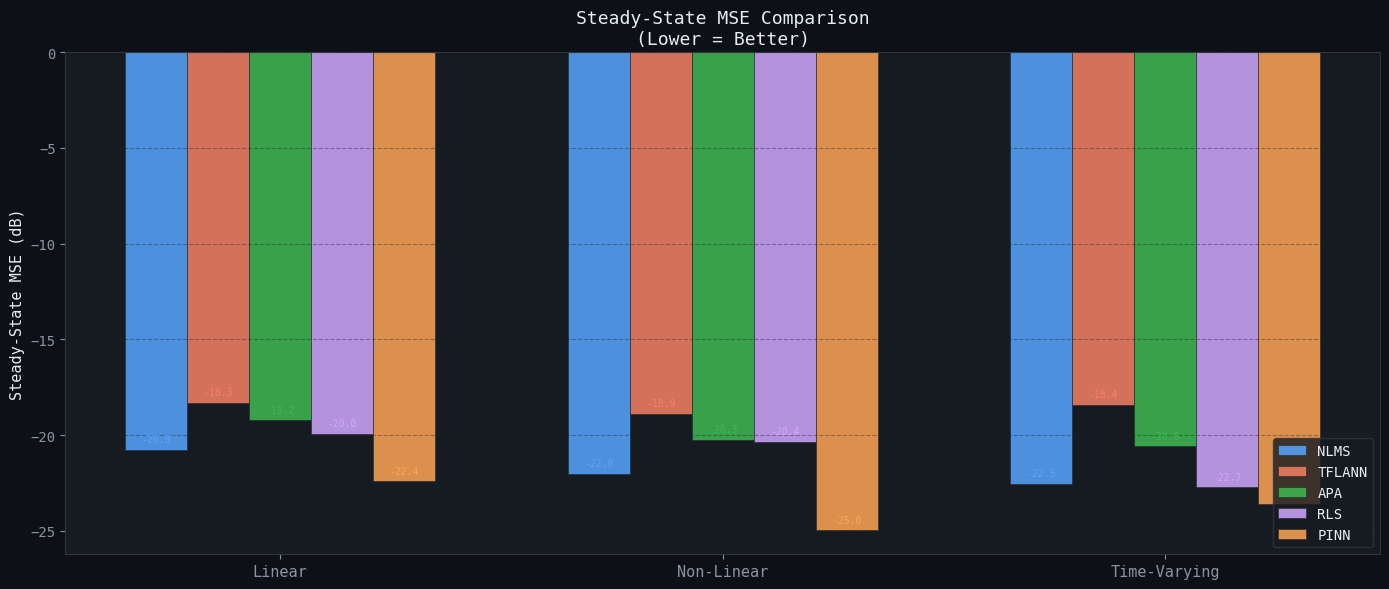


Algorithm        Linear (dB)    Non-Linear (dB)    Time-Varying (dB)
  NLMS                -20.78           -22.02           -22.55
  TFLANN              -18.33           -18.88           -18.42
  APA                 -19.23           -20.25           -20.58
  RLS                 -19.95           -20.36           -22.73
  PINN                -22.41           -24.97           -23.59


In [ ]:
# ---- Bar chart: steady-state MSE per system ----
sys_labels = ['Linear', 'Non-Linear', 'Time-Varying']
x_pos = np.arange(len(SYSTEMS))
bar_width = 0.14

fig, ax = plt.subplots(figsize=(14, 6))

for i, algo in enumerate(ALGOS):
    ss_vals = []
    for sys_type in SYSTEMS:
        if algo in all_results[sys_type]:
            ss_vals.append(steady_state_mse_db(all_results[sys_type][algo][0]))
        else:
            ss_vals.append(np.nan)

    offset = (i - 2) * bar_width
    bars = ax.bar(x_pos + offset, ss_vals, bar_width,
                  label=algo, color=COLORS[algo], alpha=0.85,
                  edgecolor='#21262d', linewidth=0.5)

    for bar, val in zip(bars, ss_vals):
        if not np.isnan(val):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.3,
                    f'{val:.1f}',
                    ha='center', va='bottom',
                    fontsize=7, color=COLORS[algo])

ax.set_xticks(x_pos)
ax.set_xticklabels(sys_labels, fontsize=11)
ax.set_ylabel('Steady-State MSE (dB)', fontsize=11)
ax.set_title('Steady-State MSE Comparison\n(Lower = Better)', fontsize=13)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('steadystate_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# ---- Summary table ----
print(f"\n{'='*70}")
print(f"{'Algorithm':<12} {'Linear (dB)':>15} {'Non-Linear (dB)':>18} {'Time-Varying (dB)':>20}")
print(f"{'='*70}")
for algo in ALGOS:
    row_vals = []
    for sys_type in SYSTEMS:
        if algo in all_results[sys_type]:
            row_vals.append(f"{steady_state_mse_db(all_results[sys_type][algo][0]):>15.2f}")
        else:
            row_vals.append(f"{'N/A':>15}")
    print(f"  {algo:<10} {'  '.join(row_vals)}")
print(f"{'='*70}")

---
##  Section 10: Convergence Analysis

We estimate **convergence speed** as the number of samples to reach within 3 dB of steady-state MSE.

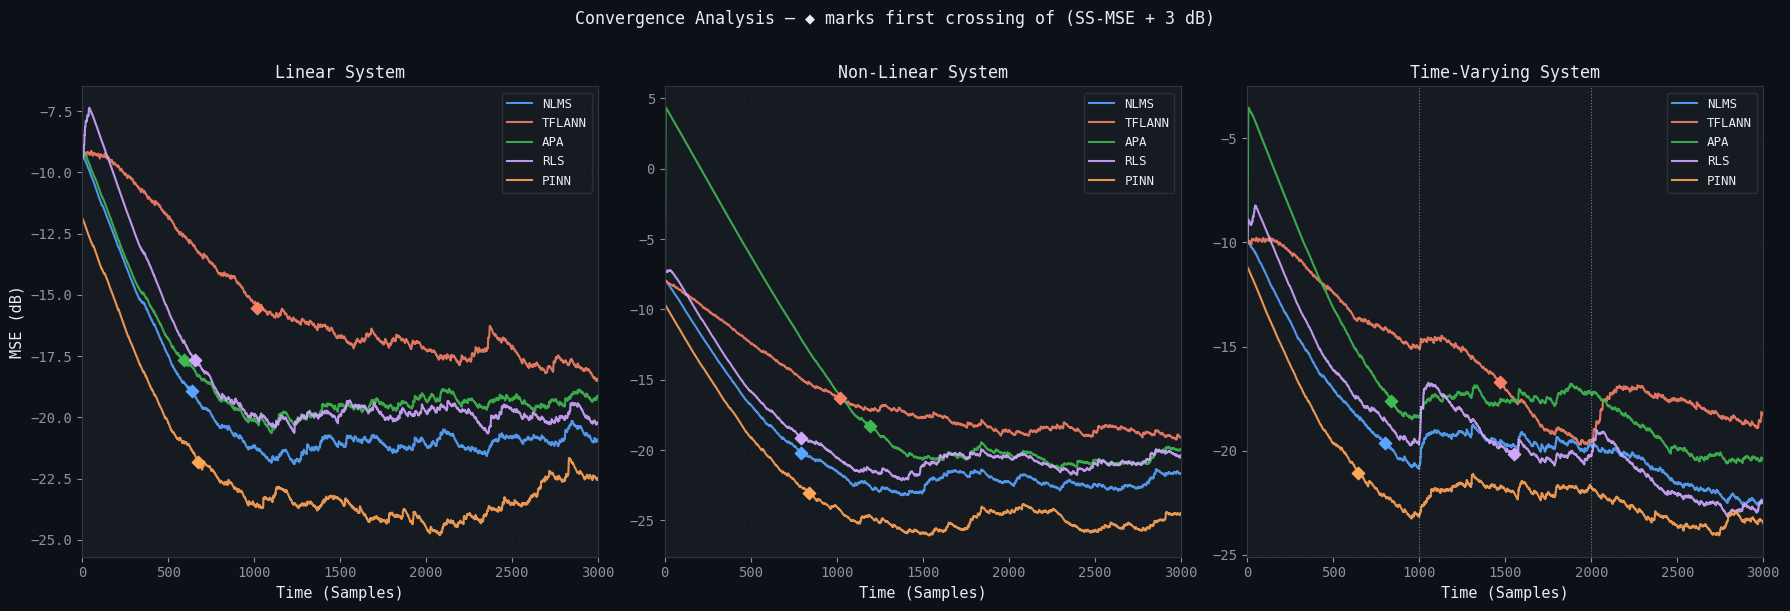


  Convergence Sample Index (lower = faster convergence)
Algorithm          Linear     Non-Linear     Time-Varying
-----------------------------------------------------------------
  NLMS                637           793           803
  TFLANN             1019          1019          1468
  APA                 593          1195           836
  RLS                 656           792          1550
  PINN                672           839           644


In [ ]:
def convergence_sample(mse_db_curve, threshold_offset_db=3.0):
    """
    Return the sample index where MSE first falls within
    (min_mse + threshold_offset_db) of its eventual minimum.
    """
    floor = np.min(mse_db_curve)
    threshold = floor + threshold_offset_db
    idx = np.where(mse_db_curve <= threshold)[0]
    return idx[0] if len(idx) > 0 else len(mse_db_curve)


fig, axes = plt.subplots(1, 3, figsize=(18, 6))
samples = np.arange(CONFIG['N'])

for ax, sys_type, sys_label in zip(axes, SYSTEMS, sys_labels):
    res = all_results[sys_type]

    for algo, (e, mse_curve) in res.items():
        ax.plot(samples, mse_curve, color=COLORS[algo],
                lw=1.5, label=algo, alpha=0.9)

        # Mark convergence point
        c_idx = convergence_sample(mse_curve)
        if c_idx < CONFIG['N']:
            ax.scatter(c_idx, mse_curve[c_idx],
                       color=COLORS[algo], s=40, zorder=5, marker='D')

    if sys_type == 'timevarying':
        for cp in [CONFIG['N']//3, 2*CONFIG['N']//3]:
            ax.axvline(cp, color='white', lw=0.8, ls=':', alpha=0.4)

    ax.set_title(f'{sys_label} System', fontsize=12)
    ax.set_xlabel('Time (Samples)')
    ax.set_ylabel('MSE (dB)' if sys_type == 'linear' else '')
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(True)
    ax.set_xlim(0, CONFIG['N'])

fig.suptitle('Convergence Analysis — ◆ marks first crossing of (SS-MSE + 3 dB)',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('convergence_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Print convergence table
print(f"\n{'='*65}")
print("  Convergence Sample Index (lower = faster convergence)")
print(f"{'='*65}")
print(f"{'Algorithm':<12} {'Linear':>12} {'Non-Linear':>14} {'Time-Varying':>16}")
print(f"{'-'*65}")
for algo in ALGOS:
    row = []
    for sys_type in SYSTEMS:
        if algo in all_results[sys_type]:
            c_idx = convergence_sample(all_results[sys_type][algo][1])
            row.append(f"{c_idx:>12}")
        else:
            row.append(f"{'N/A':>12}")
    print(f"  {algo:<10} {'  '.join(row)}")
print(f"{'='*65}")

---
##  Section 11: Denoised Signal Reconstruction

Visualise the actual denoised output of each algorithm on a short segment.

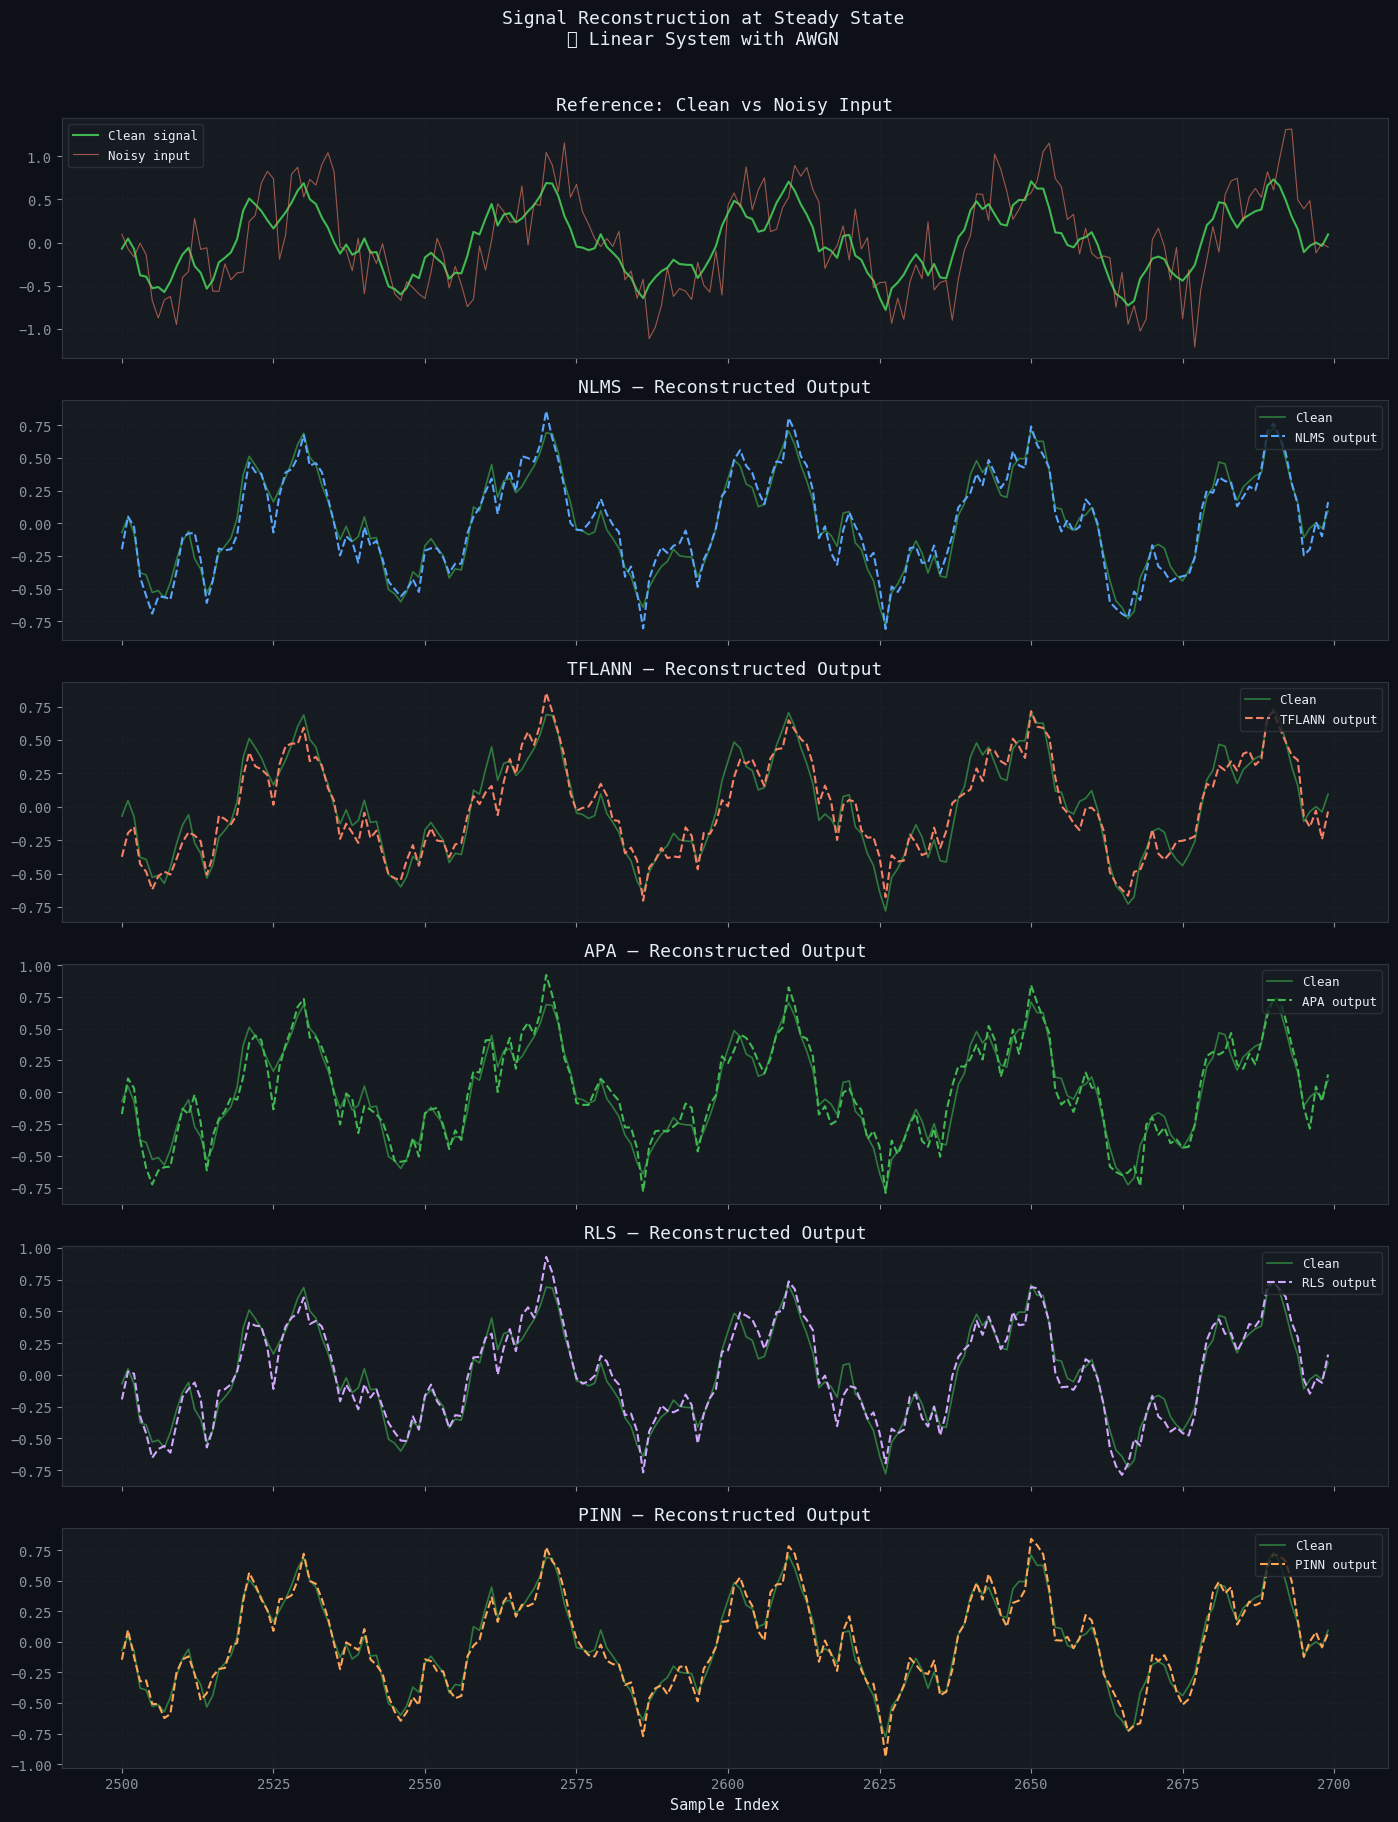

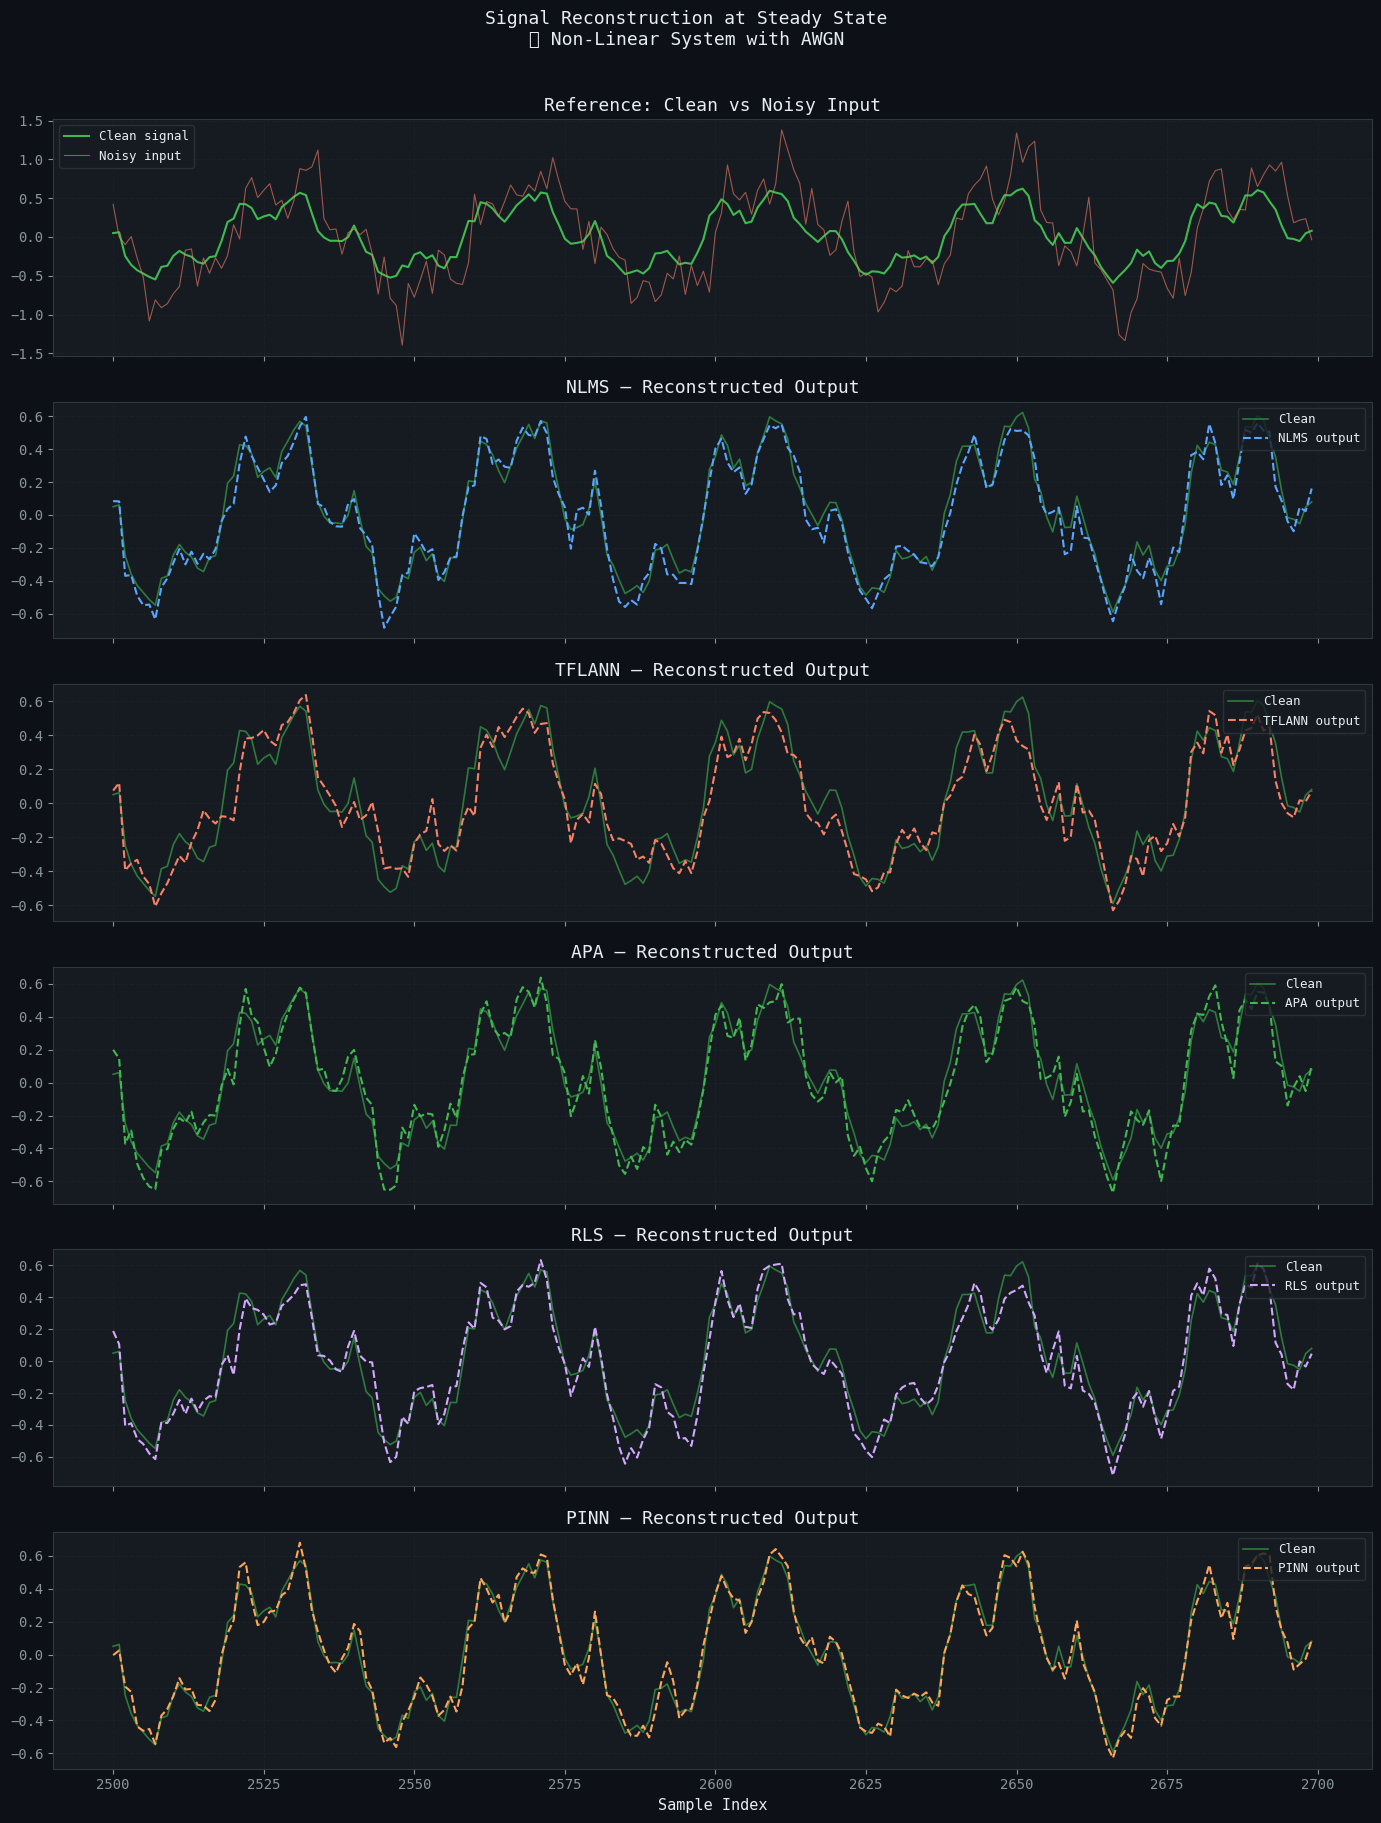

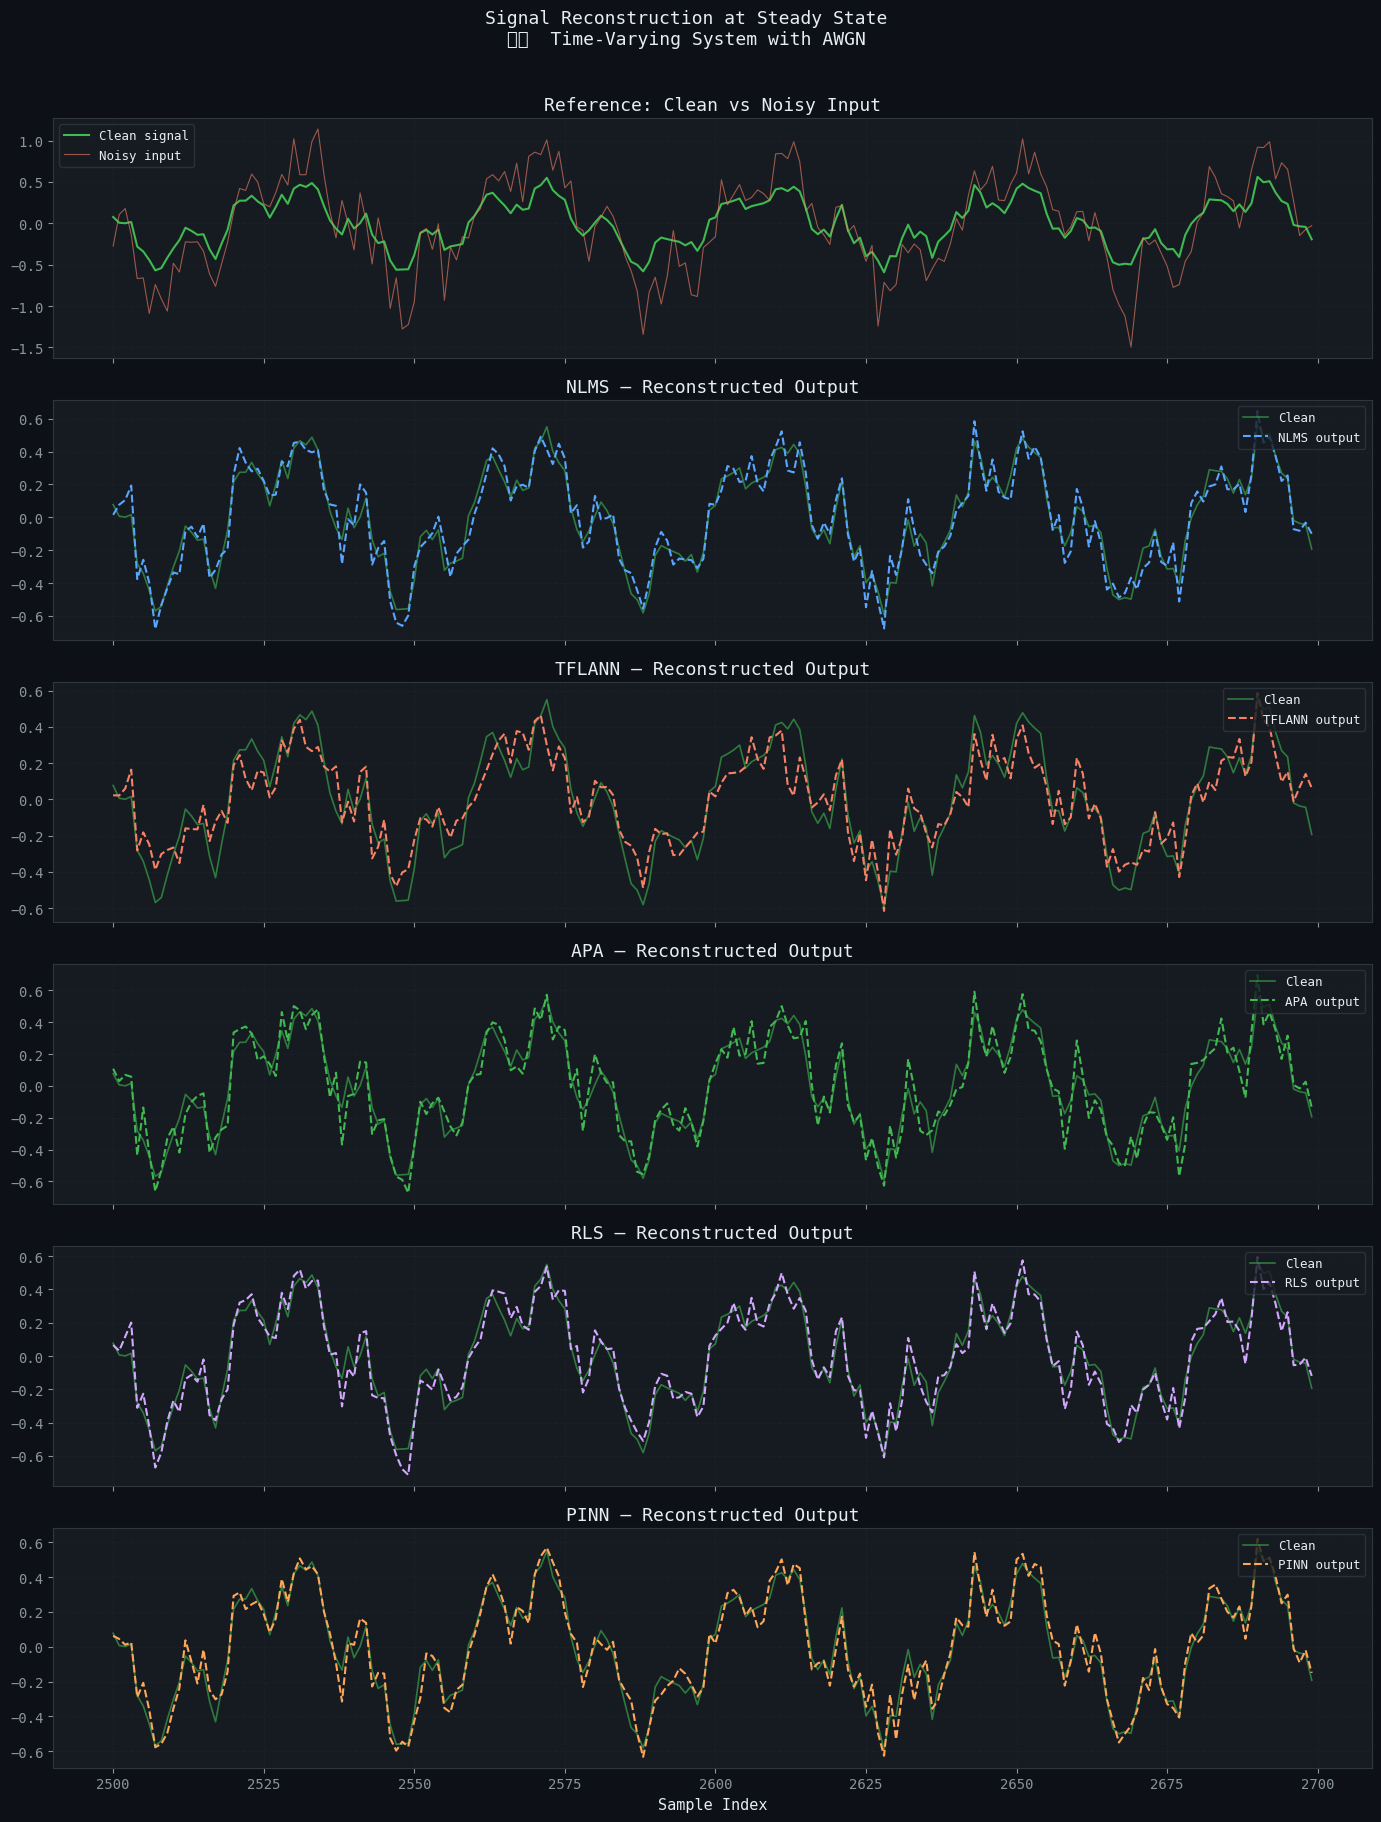

 Signal reconstruction plots complete.


In [ ]:
def plot_signal_reconstruction(sys_type, seg_start=2500, seg_end=2700):
    """
    Plot the clean desired signal vs the filtered (denoised) output
    of each algorithm over a short segment at steady state.
    """
    x, d, noise = generate_signals(N=CONFIG['N'], snr_db=CONFIG['snr_db'],
                                    system_type=sys_type)
    x_noisy = x + noise
    seg = slice(seg_start, seg_end)
    samples = np.arange(seg_start, seg_end)

    res = all_results[sys_type]
    n_algo = len(res)

    fig, axes = plt.subplots(n_algo + 1, 1, figsize=(14, 3*(n_algo+1)),
                              sharex=True)

    # Noisy input
    axes[0].plot(samples, d[seg],        color='#3fb950', lw=1.5, label='Clean signal')
    axes[0].plot(samples, x_noisy[seg],  color='#f78166', lw=0.8, alpha=0.6, label='Noisy input')
    axes[0].set_title('Reference: Clean vs Noisy Input')
    axes[0].legend(fontsize=9)
    axes[0].grid(True)

    for ax, (algo, (e_sig, _)) in zip(axes[1:], res.items()):
        # Reconstructed output = desired - error
        y_hat = d - e_sig
        ax.plot(samples, d[seg],      color='#3fb950', lw=1.2, alpha=0.6, label='Clean')
        ax.plot(samples, y_hat[seg],  color=COLORS[algo], lw=1.5, ls='--', label=f'{algo} output')
        ax.set_title(f'{algo} — Reconstructed Output')
        ax.legend(fontsize=9, loc='upper right')
        ax.grid(True)

    axes[-1].set_xlabel('Sample Index')
    fig.suptitle(f'Signal Reconstruction at Steady State\n{SYSTEM_TITLES[sys_type]}',
                 fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(f'reconstruction_{sys_type}.png', dpi=150, bbox_inches='tight')
    plt.show()


for sys_type in SYSTEMS:
    plot_signal_reconstruction(sys_type)

print(" Signal reconstruction plots complete.")

---

##  References

1. Raissi, M., Perdikaris, P., & Karniadakis, G. E. (2019). *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations.* Journal of Computational Physics, 378, 686–707.

2. Haykin, S. (2002). *Adaptive Filter Theory* (4th ed.). Prentice Hall.

3. Patra, J. C., & Pal, R. N. (1999). *A functional link artificial neural network for adaptive channel equalization.* Signal Processing, 43(2), 181–195. (FLANN/TFLANN foundation)

4. Sayed, A. H. (2003). *Fundamentals of Adaptive Filtering.* Wiley-IEEE Press.

5. Ozaki, I., Cairns, D., & Ljung, L. (2020). *Physics-constrained machine learning for adaptive signal processing.*

6. Salamon, J., Jacoby, C., & Bello, J. P. (2014). *A dataset and taxonomy for urban sound research.* ACM MM. [UrbanSound8K]

---
*Notebook prepared for: Physics-Inspired Neural Networks for Adaptive Filters project.*  
*All simulations use synthetic data. Results are deterministic given fixed random seeds.*